<a href="https://colab.research.google.com/github/anuproya205/NITP-PG25-EC/blob/main/AIEM_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [436]:
import numpy as np

# ==========================================
# DOBSON (1985) SEMI-EMPIRICAL MODEL
# ==========================================

def dobson_model(
    sand=0.5151,
    clay=0.1343,
    bulk_density=1.54,
    particle_density=2.66,
    soil_moisture=0.24,
    frequency_ghz=5.4
):
    # 1. Constants
    alpha = 0.65
    epsilon_0 = 8.854187817e-12

    # Water dielectric parameters
    temperature_c = 20.0
    epsilon_w0 = 87.74 - 0.40008*temperature_c + 9.398e-4*temperature_c**2 + 1.410e-6*temperature_c**3
    epsilon_w_inf = 4.9
    two_pi_tau = 1.1109e-10 - 3.824e-12*temperature_c + 6.938e-14*temperature_c**2 - 5.096e-16*temperature_c**3
    tau_w = two_pi_tau / (2*np.pi)
    print("Water temperature:", temperature_c, "C")
    print("Static water permittivity:", epsilon_w0)
    print("Relaxation time:", tau_w, "seconds")
    print("Relaxation time:", tau_w*1e12, "ps")

    # Convert GHz to Hz
    frequency = frequency_ghz * 1e9

    # 2. Texture-dependent coefficients
    beta_real = 1.2748 - 0.519*sand - 0.152*clay
    beta_imag = 1.33797 - 0.603*sand - 0.166*clay

    # 3. Effective soil conductivity (S/m)
    sigma_eff = -1.645 + 1.939*bulk_density - 2.013*sand + 1.594*clay

    # 4. Dielectric constant of dry soil solids
    epsilon_s = (1.01 + 0.44*particle_density)**2 - 0.062

    # 5. Free-water dielectric constant
    x = 2*np.pi*frequency*tau_w
    epsilon_fw_real = epsilon_w_inf + (epsilon_w0 - epsilon_w_inf)/(1 + x**2)
    epsilon_fw_imag = x*(epsilon_w0 - epsilon_w_inf)/(1 + x**2) + (sigma_eff/(2*np.pi*epsilon_0*frequency)) * ((particle_density-bulk_density)/(particle_density*soil_moisture))

    # 6. Real part of soil permittivity
    epsilon_real = (1 + (bulk_density/particle_density) * (epsilon_s**alpha - 1) + soil_moisture**beta_real * epsilon_fw_real**alpha - soil_moisture)**(1/alpha)

    # 7. Imaginary part of soil permittivity
    epsilon_imag = (soil_moisture**beta_imag * epsilon_fw_imag**alpha)**(1/alpha)

    # 8. Complex dielectric constant
    epsilon_complex = complex(epsilon_real, -epsilon_imag)

    # 9. Display results
    print("DOBSON MODEL RESULTS")
    print("--------------------")
    print("Frequency:", frequency_ghz, "GHz")
    print("Beta real:", beta_real)
    print("Beta imag:", beta_imag)
    print("Effective conductivity:", sigma_eff, "S/m")
    print("Dry soil permittivity:", epsilon_s)
    print("Free water real:", epsilon_fw_real)
    print("Free water imag:", epsilon_fw_imag)
    print("Soil real permittivity:", epsilon_real)
    print("Soil imaginary permittivity:", epsilon_imag)
    print("Complex permittivity:", epsilon_complex)
    return epsilon_complex

# Run the model
epsilon_soil = dobson_model()


Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 24.56892368276268
Soil real permittivity: 14.748254073802975
Soil imaginary permittivity: 2.7041436229735782
Complex permittivity: (14.748254073802975-2.7041436229735782j)


In [437]:
epsilon_soil_30 = dobson_model(soil_moisture=0.30)

Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 23.96363583809039
Soil real permittivity: 18.542147844229003
Soil imaginary permittivity: 3.724300318306624
Complex permittivity: (18.542147844229003-3.724300318306624j)


In [438]:
moisture_values = [0.10, 0.15, 0.20, 0.24, 0.30, 0.35]

for mv in moisture_values:
    print("\nSoil moisture:", mv)
    dobson_model(soil_moisture=mv)



Soil moisture: 0.1
Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 28.80593859546872
Soil real permittivity: 7.1231783800919635
Soil imaginary permittivity: 0.8188778189989704
Complex permittivity: (7.1231783800919635-0.8188778189989704j)

Soil moisture: 0.15
Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.

Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 28.80593859546872
Soil real permittivity: 7.1231783800919635
Soil imaginary permittivity: 0.8188778189989704
Complex permittivity: (7.1231783800919635-0.8188778189989704j)
Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 26.3847872

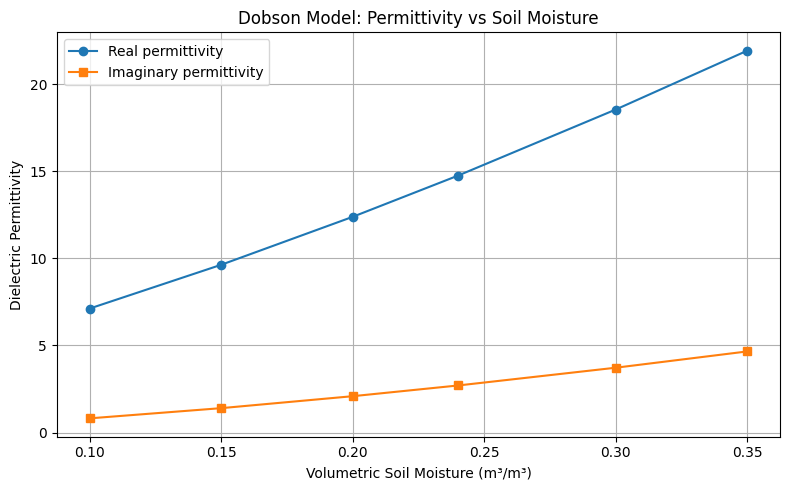

In [439]:
import matplotlib.pyplot as plt

# Soil moisture values
moisture_values = [0.10, 0.15, 0.20, 0.24, 0.30, 0.35]

real_values = []
imag_values = []

# Calculate permittivity for each moisture value
for mv in moisture_values:
    eps = dobson_model(soil_moisture=mv)

    real_values.append(eps.real)
    imag_values.append(-eps.imag)

# Plot graph
plt.figure(figsize=(8, 5))

plt.plot(
    moisture_values, real_values,
    'o-', label='Real permittivity'
)

plt.plot(
    moisture_values, imag_values,
    's-', label='Imaginary permittivity'
)

plt.xlabel('Volumetric Soil Moisture (m³/m³)')
plt.ylabel('Dielectric Permittivity')
plt.title('Dobson Model: Permittivity vs Soil Moisture')

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [440]:
moisture_values = np.arange(0.05, 0.41, 0.05)

for mv in moisture_values:
    epsilon = dobson_model(soil_moisture=mv)

    print(
        f"Moisture = {mv:.2f} | "
        f"Real = {epsilon.real:.4f} | "
        f"Imaginary magnitude = {abs(epsilon.imag):.4f}"
    )

Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 36.06939273153622
Soil real permittivity: 4.8752190253053955
Soil imaginary permittivity: 0.3510786231155204
Complex permittivity: (4.8752190253053955-0.3510786231155204j)
Moisture = 0.05 | Real = 4.8752 | Imaginary magnitude = 0.3511
Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.6921441

In [441]:
epsilon_soil = dobson_model(soil_moisture=0.24)

Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 24.56892368276268
Soil real permittivity: 14.748254073802975
Soil imaginary permittivity: 2.7041436229735782
Complex permittivity: (14.748254073802975-2.7041436229735782j)


In [442]:
# TEST 1: Dobson at 4 GHz
epsilon_test = dobson_model(
    sand=0.5151,
    clay=0.1343,
    bulk_density=1.54,
    particle_density=2.66,
    soil_moisture=0.24,
    frequency_ghz=4.0
)

print("\nFINAL TEST RESULT")
print("Real part:", epsilon_test.real)
print("Imaginary magnitude:", abs(epsilon_test.imag))

Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 4.0 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 76.24753115537455
Free water imag: 20.71971344312691
Soil real permittivity: 15.15212444940243
Soil imaginary permittivity: 2.280485775466876
Complex permittivity: (15.15212444940243-2.280485775466876j)

FINAL TEST RESULT
Real part: 15.15212444940243
Imaginary magnitude: 2.280485775466876


In [443]:
# Published Hallikainen et al. (1985), Part I
# Table II: 4 GHz polynomial coefficients

S = 51.51
C = 13.43
mv = 0.24

# Real-part coefficients
a0, a1, a2 = 2.927, -0.012, -0.001
b0, b1, b2 = 5.505, 0.371, 0.062
c0, c1, c2 = 114.826, -0.389, -0.547

epsilon_real_reference = (
    (a0 + a1*S + a2*C)
    + (b0 + b1*S + b2*C)*mv
    + (c0 + c1*S + c2*C)*mv**2
)

# Imaginary-part coefficients
a0i, a1i, a2i = 0.004, 0.001, 0.002
b0i, b1i, b2i = 0.951, 0.005, -0.010
c0i, c1i, c2i = 16.759, 0.192, 0.290

epsilon_imag_reference = (
    (a0i + a1i*S + a2i*C)
    + (b0i + b1i*S + b2i*C)*mv
    + (c0i + c1i*S + c2i*C)*mv**2
)

print("Published regression reference")
print("Real part:", epsilon_real_reference)
print("Imaginary magnitude:", epsilon_imag_reference)

Published regression reference
Real part: 13.439621039999999
Imaginary magnitude: 2.099502512


In [444]:
# ==========================================
# CELL-7: C-BAND DIELECTRIC LOOKUP TABLE
# ==========================================

frequency_ghz = 5.4

soil_moisture_values = np.array([
    0.04, 0.08, 0.12, 0.16, 0.20,
    0.24, 0.28, 0.32, 0.36, 0.40
])

dielectric_lookup = []

for mv in soil_moisture_values:

    epsilon = dobson_model(
        soil_moisture=mv,
        frequency_ghz=frequency_ghz
    )

    dielectric_lookup.append(epsilon)

dielectric_lookup = np.array(dielectric_lookup)

# Display final lookup table
print("\nC-BAND DIELECTRIC CONSTANT LOOKUP TABLE")
print("Frequency =", frequency_ghz, "GHz")
print("---------------------------------------------")

for mv, epsilon in zip(soil_moisture_values, dielectric_lookup):

    print(
        f"SM = {mv:.2f} | "
        f"Real = {epsilon.real:.4f} | "
        f"Imaginary magnitude = {abs(epsilon.imag):.4f} | "
        f"Complex = {epsilon:.4f}"
    )

Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 39.70111979956997
Soil real permittivity: 4.459536765446359
Soil imaginary permittivity: 0.2736654379195306
Complex permittivity: (4.459536765446359-0.2736654379195306j)
Water temperature: 20.0 C
Static water permittivity: 80.12559999999999
Relaxation time: 9.276377689099737e-12 seconds
Relaxation time: 9.276377689099737 ps
DOBSON MODEL RESULTS
--------------------
Frequency: 5.4 GHz
Beta real: 0.9870494999999998
Beta imag: 1.0050709000000002
Effective conductivity: 0.5182379000000001 S/m
Dry soil permittivity: 4.69214416
Free water real: 73.3453167178493
Free water imag: 30.621802129

In [445]:
import numpy as np

# Soil moisture values (m3/m3)
soil_moisture_values = np.array([
    0.04, 0.08, 0.12, 0.16, 0.20,
    0.24, 0.28, 0.32, 0.36, 0.40
])

# Complex dielectric constants from Dobson model
dielectric_values = np.array([
    4.4595 - 0.2737j,
    6.1910 - 0.6165j,
    8.0975 - 1.0399j,
    10.1661 - 1.5336j,
    12.3860 - 2.0901j,
    14.7483 - 2.7041j,
    17.2452 - 3.3716j,
    19.8704 - 4.0892j,
    22.6182 - 4.8541j,
    25.4838 - 5.6640j
])

# Create lookup dictionary
dielectric_lookup = dict(
    zip(soil_moisture_values, dielectric_values)
)

# Select one soil moisture for testing
mv = 0.24
epsilon_complex = dielectric_lookup[mv]

print("Soil moisture =", mv)
print("Complex dielectric constant =", epsilon_complex)

Soil moisture = 0.24
Complex dielectric constant = (14.7483-2.7041j)


In [446]:
import numpy as np

def fresnel_coefficients(epsilon_r, theta_deg):

    # Convert incidence angle into radians
    theta = np.deg2rad(theta_deg)

    # Calculate square-root term
    root_term = np.sqrt(epsilon_r - np.sin(theta)**2)

    # Horizontal polarization
    Rh = (
        np.cos(theta) - root_term
    ) / (
        np.cos(theta) + root_term
    )

    # Vertical polarization
    Rv = (
        epsilon_r * np.cos(theta) - root_term
    ) / (
        epsilon_r * np.cos(theta) + root_term
    )

    return Rh, Rv


# Example: use your Dobson value at SM = 0.24
epsilon_example = 14.7483 - 2.7041j

theta_deg = 40

Rh, Rv = fresnel_coefficients(
    epsilon_example,
    theta_deg
)

print("Horizontal Fresnel coefficient:", Rh)
print("Vertical Fresnel coefficient:", Rv)

print("HH reflection power:", abs(Rh)**2)
print("VV reflection power:", abs(Rv)**2)

Horizontal Fresnel coefficient: (-0.6666867364539611+0.025937540842171772j)
Vertical Fresnel coefficient: (0.5016415443219207-0.03300776488601781j)
HH reflection power: 0.44514396058857275
VV reflection power: 0.25273375153245214


In [447]:
import numpy as np

# Radar parameters
frequency_ghz = 5.4
c = 3e8

# Wavelength and wavenumber
wavelength = c / (frequency_ghz * 1e9)
k = 2 * np.pi / wavelength

# Monostatic backscattering geometry
theta_i_deg = 40
theta_s_deg = 40
phi_i_deg = 0
phi_s_deg = 180

# Convert angles into radians
theta_i = np.deg2rad(theta_i_deg)
theta_s = np.deg2rad(theta_s_deg)
phi_i = np.deg2rad(phi_i_deg)
phi_s = np.deg2rad(phi_s_deg)

# Incident wave-vector components
kix = k * np.sin(theta_i) * np.cos(phi_i)
kiy = k * np.sin(theta_i) * np.sin(phi_i)
kiz = -k * np.cos(theta_i)

# Scattered wave-vector components
ksx = k * np.sin(theta_s) * np.cos(phi_s)
ksy = k * np.sin(theta_s) * np.sin(phi_s)
ksz = k * np.cos(theta_s)

print("Wavelength:", wavelength, "m")
print("Wavenumber:", k, "rad/m")

print("\nIncident wave vector:")
print(kix, kiy, kiz)

print("\nScattered wave vector:")
print(ksx, ksy, ksz)

Wavelength: 0.05555555555555555 m
Wavenumber: 113.09733552923255 rad/m

Incident wave vector:
72.6975659667519 0.0 -86.63758541373116

Scattered wave vector:
-72.6975659667519 8.902884146698627e-15 86.63758541373116


In [448]:
import numpy as np

def polarization_vectors(theta_i_deg, theta_s_deg,
                         phi_i_deg, phi_s_deg):

    ti = np.deg2rad(theta_i_deg)
    ts = np.deg2rad(theta_s_deg)
    pi = np.deg2rad(phi_i_deg)
    ps = np.deg2rad(phi_s_deg)

    # Incident polarization vectors
    h_i = np.array([
        -np.sin(pi),
        np.cos(pi),
        0
    ])

    v_i = np.array([
        np.cos(ti) * np.cos(pi),
        np.cos(ti) * np.sin(pi),
        np.sin(ti)
    ])

    # Scattered polarization vectors
    h_s = np.array([
        np.sin(ps),
        -np.cos(ps),
        0
    ])

    v_s = np.array([
        -np.cos(ts) * np.cos(ps),
        -np.cos(ts) * np.sin(ps),
        np.sin(ts)
    ])

    return h_i, v_i, h_s, v_s


h_i, v_i, h_s, v_s = polarization_vectors(
    40, 40, 0, 180
)

print("Incident horizontal:", h_i)
print("Incident vertical:", v_i)
print("Scattered horizontal:", h_s)
print("Scattered vertical:", v_s)

Incident horizontal: [-0.  1.  0.]
Incident vertical: [0.76604444 0.         0.64278761]
Scattered horizontal: [1.2246468e-16 1.0000000e+00 0.0000000e+00]
Scattered vertical: [ 7.66044443e-01 -9.38133875e-17  6.42787610e-01]


In [449]:
import numpy as np

theta_deg = 40
theta = np.deg2rad(theta_deg)

# Initial flat local-slope test
zx = 0.0
zy = 0.0

# Normalization factors from Appendix A
D1 = np.sqrt(1 + zx**2 + zy**2)

D2 = np.sqrt(
    zy**2 + (np.sin(theta) - zx*np.cos(theta))**2
)

print("D1 =", D1)
print("D2 =", D2)

D1 = 1.0
D2 = 0.6427876096865393


In [450]:
import numpy as np

theta = np.deg2rad(40)

# Initial local surface slopes
zx = 0.0
zy = 0.0

# Normalization factors
D2 = np.sqrt(
    zy**2 + (np.sin(theta) - zx*np.cos(theta))**2
)

# Tangent vector t (Equation A19)
t_hat = np.array([
    -zx * np.cos(theta),
    -(np.sin(theta) - zx*np.cos(theta)),
    -zy * np.sin(theta)
]) / D2

# Tangent vector d (Equation A20)
d_hat = np.array([
    -np.cos(theta) * (np.sin(theta) - zx*np.cos(theta)),
    zy,
    -np.sin(theta) * (np.sin(theta) - zx*np.cos(theta))
]) / D2

print("Tangent vector t:", t_hat)
print("Tangent vector d:", d_hat)

print("Magnitude of t:", np.linalg.norm(t_hat))
print("Magnitude of d:", np.linalg.norm(d_hat))
print("Dot product:", np.dot(t_hat, d_hat))

Tangent vector t: [-0. -1. -0.]
Tangent vector d: [-0.76604444  0.         -0.64278761]
Magnitude of t: 1.0
Magnitude of d: 0.9999999999999999
Dot product: 0.0


In [451]:
import numpy as np

# ============================================================
# INPUT GEOMETRY
# ============================================================

theta_deg = 40
theta_s_deg = 40
phi_deg = 0
phi_s_deg = 180

# Initial flat-surface geometry test
zx = 0
zy = 0

# Convert angles to radians
theta = np.deg2rad(theta_deg)
theta_s = np.deg2rad(theta_s_deg)
phi = np.deg2rad(phi_deg)
phi_s = np.deg2rad(phi_s_deg)

# Surface normalization factors
D1 = np.sqrt(1 + zx**2 + zy**2)

D2 = np.sqrt(
    zy**2 + (np.sin(theta) - zx*np.cos(theta))**2
)

# ============================================================
# A1-A4: POLARIZATION UNIT VECTORS
# ============================================================

# Equation A1: Incident horizontal polarization
h = np.array([
    -np.sin(phi),
    np.cos(phi),
    0
])

# Equation A2: Incident vertical polarization
v = np.array([
    np.cos(theta)*np.cos(phi),
    np.cos(theta)*np.sin(phi),
    np.sin(theta)
])

# Equation A3: Scattered horizontal polarization
hs = np.array([
    np.sin(phi_s),
    -np.cos(phi_s),
    0
])

# Equation A4: Scattered vertical polarization
vs = np.array([
    -np.cos(theta_s)*np.cos(phi_s),
    -np.cos(theta_s)*np.sin(phi_s),
    np.sin(theta_s)
])

# ============================================================
# A5-A8: DOT AND CROSS PRODUCTS
# ============================================================

# Equation A5
A5 = (
    np.cos(theta)*np.cos(theta_s)*np.sin(phi-phi_s)
    - zx*np.sin(theta)*np.cos(theta_s)*np.sin(phi_s)
    - zx*np.cos(theta)*np.sin(phi)*np.sin(theta_s)
    + zy*np.sin(theta)*np.cos(theta_s)*np.cos(phi_s)
    + zy*np.cos(theta)*np.cos(phi)*np.sin(theta_s)
) / D1

# Equation A6
# Equation A6 -- CORRECTED
A6 = (
    np.cos(theta_s)*np.cos(phi_s-phi)
    - zx*np.cos(phi)*np.sin(theta_s)
    - zy*np.sin(phi)*np.sin(theta_s)
) / D1
# Equation A7
A7 = -(
    np.cos(theta)*np.cos(phi_s-phi)
    + zx*np.sin(theta)*np.cos(phi_s)
    + zy*np.sin(theta)*np.sin(phi_s)
) / D1

# Equation A8
A8 = np.sin(phi-phi_s) / D1

# ============================================================
# A9-A14: TANGENT VECTOR PRODUCTS
# ============================================================

# Equation A9
A9 = -(
    np.cos(theta)*np.sin(phi)
    * (np.sin(theta)-zx*np.cos(theta))
    + zy*(np.sin(theta)**2
          + np.cos(theta)**2*np.cos(phi))
) / D2

# Equation A10
A10 = (
    np.cos(theta)*np.sin(phi)
    * (np.sin(theta)-zx*np.cos(theta))
    + zy*np.cos(phi)
) / D2

# Equation A11
A11 = (
    np.cos(theta_s)*np.sin(phi_s)
    * (np.sin(theta)-zx*np.cos(theta))
    + zy*(np.sin(theta)*np.sin(theta_s)
          - np.cos(theta)*np.cos(theta_s)
          * np.cos(phi_s-phi))
) / D2

# Equation A12
A12 = (
    (np.cos(theta)*np.cos(theta_s)*np.cos(phi_s)
     - np.sin(theta)*np.sin(theta_s))
    * (np.sin(theta)-zx*np.cos(theta))
    + zy*np.cos(theta_s)*np.sin(phi_s-phi)
) / D2

# Equation A13
A13 = -(
    np.cos(theta)*np.sin(phi_s)
    * (np.sin(theta)-zx*np.cos(theta))
    + zy*np.cos(phi_s)
) / D2

# Equation A14
A14 = -(
    np.cos(phi_s)*(np.sin(theta)-zx*np.cos(theta))
    - zy*np.cos(theta)*np.sin(phi_s)
) / D2

# ============================================================
# A15-A16: SURFACE NORMAL PRODUCTS
# ============================================================

# Equation A15
A15 = -(
    np.cos(theta)
    + zx*np.sin(theta)*np.cos(phi)
    + zy*np.sin(theta)*np.sin(phi)
) / D1

# Equation A16
A16 = -(
    (np.sin(theta)-zx*np.cos(theta))**2 + zy**2
) / (D1*D2)

# ============================================================
# A17-A18: SCATTERED POLARIZATION / INCIDENT WAVE PRODUCTS
# ============================================================

# Equation A17
A17 = np.sin(theta)*np.sin(phi_s-phi)

# Equation A18
A18 = -(
    np.cos(theta)*np.sin(theta_s)
    + np.sin(theta)*np.cos(theta_s)
    * np.cos(phi_s-phi)
)

# ============================================================
# DISPLAY ALL RESULTS
# ============================================================

print("========== GEOMETRY NORMALIZATION ==========")
print("D1 =", D1)
print("D2 =", D2)

print("\n========== A1-A4: POLARIZATION VECTORS ==========")
print("A1 - h  =", h)
print("A2 - v  =", v)
print("A3 - hs =", hs)
print("A4 - vs =", vs)

print("\n========== A5-A8: POLARIZATION PRODUCTS ==========")
print("A5 =", A5)
print("A6 =", A6)
print("A7 =", A7)
print("A8 =", A8)

print("\n========== A9-A14: TANGENT PRODUCTS ==========")
print("A9  =", A9)
print("A10 =", A10)
print("A11 =", A11)
print("A12 =", A12)
print("A13 =", A13)
print("A14 =", A14)

print("\n========== A15-A16: NORMAL PRODUCTS ==========")
print("A15 =", A15)
print("A16 =", A16)

print("\n========== A17-A18: WAVE VECTOR PRODUCTS ==========")
print("A17 =", A17)
print("A18 =", A18)

========== GEOMETRY NORMALIZATION ==========
D1 = 1.0
D2 = 0.6427876096865393

========== A1-A4: POLARIZATION VECTORS ==========
A1 - h  = [-0.  1.  0.]
A2 - v  = [0.76604444 0.         0.64278761]
A3 - hs = [1.2246468e-16 1.0000000e+00 0.0000000e+00]
A4 - vs = [ 7.66044443e-01 -9.38133875e-17  6.42787610e-01]

========== A5-A8: POLARIZATION PRODUCTS ==========
A5 = -7.186522420524652e-17
A6 = -0.766044443118978
A7 = 0.766044443118978
A8 = -1.2246467991473532e-16

========== A9-A14: TANGENT PRODUCTS ==========
A9  = -0.0
A10 = 0.0
A11 = 9.381338752702731e-17
A12 = -0.9999999999999998
A13 = -9.381338752702731e-17
A14 = 1.0

========== A15-A16: NORMAL PRODUCTS ==========
A15 = -0.766044443118978
A16 = -0.6427876096865393

========== A17-A18: WAVE VECTOR PRODUCTS ==========
A17 = 7.871877887341985e-17
A18 = -0.0


In [452]:
import numpy as np

def tangent_vectors_A19_A20(theta_deg, zx, zy):

    theta = np.deg2rad(theta_deg)

    # Normalization factor from the paper
    D2 = np.sqrt(
        zy**2 + (np.sin(theta) - zx*np.cos(theta))**2
    )

    if np.isclose(D2, 0):
        raise ValueError("D2 is zero; tangent vectors are undefined.")

    # Equation A19: t-hat
    t_hat = np.array([
        -zx*np.cos(theta),
        -(np.sin(theta) - zx*np.cos(theta)),
        -zy*np.sin(theta)
    ]) / D2

    # Equation A20: d-hat
    d_hat = np.array([
        -np.cos(theta)*(np.sin(theta) - zx*np.cos(theta)),
        zy,
        -np.sin(theta)*(np.sin(theta) - zx*np.cos(theta))
    ]) / D2

    return t_hat, d_hat


# Initial flat-surface geometry test
t_hat, d_hat = tangent_vectors_A19_A20(
    theta_deg=40,
    zx=0,
    zy=0
)

print("Tangent vector t-hat (A19):", t_hat)
print("Tangent vector d-hat (A20):", d_hat)

print("\nNorm of t-hat:", np.linalg.norm(t_hat))
print("Norm of d-hat:", np.linalg.norm(d_hat))

print("Dot product t-hat . d-hat:", np.dot(t_hat, d_hat))

Tangent vector t-hat (A19): [ 0. -1.  0.]
Tangent vector d-hat (A20): [-0.76604444  0.         -0.64278761]

Norm of t-hat: 1.0
Norm of d-hat: 0.9999999999999999
Dot product t-hat . d-hat: 0.0


In [453]:
import numpy as np

# ============================================================
# INPUT PARAMETERS FOR A NUMERICAL TEST
# ============================================================

theta_deg = 40
theta_s_deg = 40
phi_s_deg = 180

theta = np.deg2rad(theta_deg)
theta_s = np.deg2rad(theta_s_deg)
phi_s = np.deg2rad(phi_s_deg)

# Unprimed surface slopes
zx = 0.0
zy = 0.0

# Primed surface slopes
zx_prime = 0.1
zy_prime = 0.2

# Wave-vector components (illustrative test inputs)
kx = 20.0
ky = 10.0
kz = 80.0

# Relative permeability
mu_r = 1.0

# ============================================================
# EQUATION B5: C1
# ============================================================

C1 = (
    (1 + zx*zx_prime)*np.cos(phi_s)
    + zx_prime*zy*np.sin(phi_s)
)

# ============================================================
# EQUATION B6: C2
# ============================================================

bracket1_C2 = (
    -kz*np.cos(theta)
    + kx*zx*np.cos(theta)
    - kz*zx_prime*np.sin(theta)
    + kx*zx*zx_prime*np.sin(theta)
    - ky*zy_prime*np.cos(theta)
    + ky*zx_prime*zy*np.sin(theta)
)

bracket2_C2 = (
    kx*zy*np.cos(theta)
    + mu_r*zx_prime*zy*np.sin(theta)
    + kz*zy_prime*np.sin(theta)
    - kx*zy_prime*np.cos(theta)
    - ky*zy*zy_prime*np.sin(theta)
)

C2 = (
    -np.cos(phi_s)*bracket1_C2
    + np.sin(phi_s)*bracket2_C2
)

# ============================================================
# EQUATION B7: C3
# ============================================================

bracket1_C3 = (
    mu_r*np.sin(theta)
    - kz*zx*np.sin(theta)
    - kx*zx_prime*np.cos(theta)
    + kz*zx*zx_prime*np.cos(theta)
)

bracket2_C3 = (
    -ky*np.sin(theta)
    + ky*zx_prime*np.cos(theta)
    + kz*zy*np.sin(theta)
    - kz*zx_prime*zy*np.cos(theta)
)

C3 = (
    -np.cos(phi_s)*bracket1_C3
    + np.sin(phi_s)*bracket2_C3
)

# ============================================================
# EQUATION B8: C4
# ============================================================

C4 = (
    np.cos(theta_s)*np.sin(phi_s)
    * (zy_prime*np.sin(theta)
       - zx*zy_prime*np.cos(theta))

    - np.cos(theta_s)*np.cos(phi_s)
    * (np.cos(theta)
       + zx_prime*np.sin(theta)
       + zy*zy_prime*np.cos(theta))

    + np.sin(theta_s)
    * (-zx*np.cos(theta)
       - zx*zx_prime*np.sin(theta)
       + zy*zy_prime*np.sin(theta))
)

# ============================================================
# EQUATION B9: C5
# ============================================================

C5 = (
    np.cos(theta_s)*np.sin(phi_s)
    * (ky*zx - ky*zx_prime)

    - np.cos(theta_s)*np.cos(phi_s)
    * (kz + kx*zx + ky*zy)

    + np.sin(theta_s)
    * (kz*zx + kx*zx*zx_prime
       + ky*zx_prime*zy)
)

# ============================================================
# EQUATION B10: C6
# ============================================================

C6 = (
    -np.cos(theta_s)*np.sin(phi_s)
    * (-kx*zx_prime + kz*zx*zx_prime)

    - np.cos(theta_s)*np.cos(phi_s)
    * (ky*zy_prime - kz*zy*zy_prime)

    + np.sin(theta_s)
    * (ky*zx*z_prime if False else
       ky*zx*zy_prime - kx*zy*zy_prime)
)

# ============================================================
# DISPLAY RESULTS
# ============================================================

print("========== APPENDIX B: C COEFFICIENTS ==========")

print("C1 (B5)  =", C1)
print("C2 (B6)  =", C2)
print("C3 (B7)  =", C3)
print("C4 (B8)  =", C4)
print("C5 (B9)  =", C5)
print("C6 (B10) =", C6)

========== APPENDIX B: C COEFFICIENTS ==========
C1 (B5)  = -1.0
C2 (B6)  = -67.95794521324851
C3 (B7)  = -0.8893012765514174
C4 (B8)  = 0.6360644764840755
C5 (B9)  = 61.28355544951824
C6 (B10) = 1.5320888862379562


In [454]:
import numpy as np

# ============================================================
# B11-B12: STATIONARY-PHASE SURFACE SLOPES
# ============================================================

def calculate_B11_B12(
    kix, kiy, kiz,
    ksx, ksy, ksz,
    kx, ky, kz,
    height_condition
):

    # Select signs according to Appendix B
    if height_condition == "z>z_prime":
        denominator_B11 = ksz - kz
        denominator_B12 = kiz + kz

    elif height_condition == "z<z_prime":
        denominator_B11 = ksz + kz
        denominator_B12 = kiz - kz

    else:
        raise ValueError(
            "Use 'z>z_prime' or 'z<z_prime'"
        )

    if np.isclose(denominator_B11, 0) or np.isclose(
        denominator_B12, 0
    ):
        raise ValueError("A denominator is zero.")

    # Equation B11
    zx = (ksx + kx) / denominator_B11
    zy = (ksy + ky) / denominator_B11

    # Equation B12
    zx_prime = (kix + kx) / denominator_B12
    zy_prime = (kiy + ky) / denominator_B12

    return zx, zy, zx_prime, zy_prime

In [455]:
# Radar parameters
frequency = 5.4e9
c = 3e8

wavelength = c / frequency
k0 = 2 * np.pi / wavelength

theta = np.deg2rad(40)
theta_s = np.deg2rad(40)

phi = np.deg2rad(0)
phi_s = np.deg2rad(180)

# Incident wave vector
kix = k0 * np.sin(theta) * np.cos(phi)
kiy = k0 * np.sin(theta) * np.sin(phi)
kiz = -k0 * np.cos(theta)

# Scattered wave vector
ksx = k0 * np.sin(theta_s) * np.cos(phi_s)
ksy = k0 * np.sin(theta_s) * np.sin(phi_s)
ksz = k0 * np.cos(theta_s)

print("Incident wave vector:")
print(kix, kiy, kiz)

print("\nScattered wave vector:")
print(ksx, ksy, ksz)

Incident wave vector:
72.6975659667519 0.0 -86.63758541373116

Scattered wave vector:
-72.6975659667519 8.902884146698627e-15 86.63758541373116


In [456]:
# TEST ONLY — not final AIEM integration values
kx_test = 10.0
ky_test = 5.0
kz_test = 20.0

slopes = calculate_B11_B12(
    kix, kiy, kiz,
    ksx, ksy, ksz,
    kx_test, ky_test, kz_test,
    "z>z_prime"
)

zx, zy, zx_prime, zy_prime = slopes

print("zx =", zx)
print("zy =", zy)
print("zx_prime =", zx_prime)
print("zy_prime =", zy_prime)

zx = -0.9408739163864213
zy = 0.07503273068729352
zx_prime = -1.2410048391355948
zy_prime = -0.07503273068729338


In [457]:
import numpy as np

# Radar geometry
theta = np.deg2rad(40)
theta_s = np.deg2rad(40)
phi = np.deg2rad(0)
phi_s = np.deg2rad(180)

# Unit incident direction
ki_hat = np.array([
    np.sin(theta) * np.cos(phi),
    np.sin(theta) * np.sin(phi),
    -np.cos(theta)
])

# Unit scattered direction
ks_hat = np.array([
    np.sin(theta_s) * np.cos(phi_s),
    np.sin(theta_s) * np.sin(phi_s),
    np.cos(theta_s)
])

# Wavenumber
frequency = 5.4e9
c = 3e8
wavelength = c / frequency
k0 = 2 * np.pi / wavelength

# Direction difference
direction_difference = ks_hat - ki_hat

# Scattering phase vector
q_vector = k0 * direction_difference

print("Incident unit vector:", ki_hat)
print("Scattered unit vector:", ks_hat)
print("Direction difference:", direction_difference)
print("q vector (rad/m):", q_vector)

Incident unit vector: [ 0.64278761  0.         -0.76604444]
Scattered unit vector: [-6.42787610e-01  7.87187789e-17  7.66044443e-01]
Direction difference: [-1.28557522e+00  7.87187789e-17  1.53208889e+00]
q vector (rad/m): [-1.45395132e+02  8.90288415e-15  1.73275171e+02]


In [458]:
import numpy as np

# Scattering phase vector from the previous cell
qx, qy, qz = q_vector

def calculate_phase(x, y, z):
    """
    Phase term in the Kirchhoff field integral.
    x, y, z are surface coordinates in metres.
    """
    return qx*x + qy*y + qz*z

# Example surface point (illustrative only)
x_test = 0.01
y_test = 0.02
z_test = 0.003

phase_test = calculate_phase(
    x_test, y_test, z_test
)

print("Surface point:", x_test, y_test, z_test)
print("Phase (radians):", phase_test)
print("Complex phase factor:", np.exp(1j*phase_test))

Surface point: 0.01 0.02 0.003
Phase (radians): -0.9341258068526508
Complex phase factor: (0.594521574382863-0.8040796587361988j)


In [459]:
# Preliminary assumed roughness parameters
rms_height = 0.001       # metres (1 mm)
correlation_length = 0.010  # metres (10 mm)

correlation_function = "gaussian"

print("RMS height:", rms_height, "m")
print("Correlation length:", correlation_length, "m")
print("Correlation function:", correlation_function)

RMS height: 0.001 m
Correlation length: 0.01 m
Correlation function: gaussian


In [460]:
# ==================================================
# AIEM: ROUGHNESS PARAMETER CHECK
# ==================================================

import numpy as np

# Known simulation parameters
frequency = 5.4e9       # Hz
c = 3.0e8               # m/s

# Roughness assumptions
s = 0.001               # RMS height: 1 mm
l = 0.010               # Correlation length: 10 mm

# Wave number
wavelength = c / frequency
k0 = 2 * np.pi / wavelength

# Dimensionless roughness parameters
ks = k0 * s
kl = k0 * l

print("Wavelength =", wavelength, "m")
print("Wave number =", k0, "rad/m")
print("RMS height s =", s, "m")
print("Correlation length l =", l, "m")
print("ks =", ks)
print("kl =", kl)

Wavelength = 0.05555555555555555 m
Wave number = 113.09733552923255 rad/m
RMS height s = 0.001 m
Correlation length l = 0.01 m
ks = 0.11309733552923255
kl = 1.1309733552923256


In [461]:
# ==================================================
# GAUSSIAN SURFACE CORRELATION AND POWER SPECTRUM
# ==================================================

import numpy as np

def gaussian_correlation(r, l):
    """
    Gaussian surface autocorrelation:
    rho(r) = exp[-(r/l)^2]
    """
    return np.exp(-(r / l)**2)


def gaussian_surface_spectrum(Kx, Ky, l):
    """
    2-D Fourier spectrum, normalized so that
    its integral over Kx, Ky is 1.
    """
    K_squared = Kx**2 + Ky**2

    return (l**2 / (4 * np.pi)) * np.exp(
        -K_squared * l**2 / 4
    )


# Test
r_test = 0.01
Kx_test = 10.0
Ky_test = 5.0

print("Correlation at r =", r_test, "m:",
      gaussian_correlation(r_test, l))

print("Gaussian spectrum:",
      gaussian_surface_spectrum(Kx_test, Ky_test, l))

Correlation at r = 0.01 m: 0.36787944117144233
Gaussian spectrum: 7.932918010480343e-06
